# Marketing A/B Testing: From Conversion Lift to Ad-Timing Hypotheses

**Portfolio project | Python · pandas · SciPy · Statsmodels · Matplotlib**

This notebook evaluates one campaign-level question and two follow-up timing theories using the Kaggle Marketing A/B Testing dataset.

> **Analytical standard:** a high conversion rate is an observation, a statistically supported difference is an inference, and a causal scheduling recommendation requires a credible experiment.

## tl;dr

The analysis addresses three questions:

1. **Do ads outperform the PSA control group?** The observed conversion rate is higher for AD users (2.55%) than PSA users (1.79%), a difference of **+0.77 percentage points** and a relative lift of **43.1%**. The two-sided two-proportion test is statistically significant (p = 1.71 × 10⁻¹³).
2. **Do conversion rates vary by weekday among AD users?** Yes. Monday has the highest observed rate (3.32%). Monday also outperforms Tuesday after Holm correction across all 21 weekday pairwise comparisons (adjusted p = 0.00937).
3. **Which peak-ad hour performs best among AD users?** 16:00 leads descriptively at 3.09%, followed by 20:00 at 3.03%. However, the difference between these leading hours is not statistically significant (Holm-adjusted p = 1.00 across the 276 hourly pairwise comparisons).

**Bottom line:** the data supports a higher observed conversion rate in the AD group and non-uniform weekday/hour patterns. It does **not** prove that scheduling ads on Monday or at 16:00 causes more conversions. The dataset does not document the randomization process, conversion timestamp/attribution window, timezone, campaign costs, or revenue.

## 1. Business question & analysis plan

### Primary question

Does the AD group have a different conversion rate from the PSA group?

\[
H_0: p_{AD} = p_{PSA}
\qquad
H_1: p_{AD} \ne p_{PSA}
\]

A **two-sided** test is the primary analysis because the available project documentation does not establish that a one-directional hypothesis was specified before looking at the results. A one-sided test can be appropriate when the direction is genuinely pre-specified; it should not be selected after seeing which group won.

### Follow-up theory 1: weekday pattern

Among users assigned to the AD group, are conversion outcomes independent of the weekday on which they saw the most ads?

\[
H_0: p_{Mon}=p_{Tue}=\cdots=p_{Sun}
\]

The global test is followed by all 21 two-sided weekday pairwise comparisons, with Holm correction.

### Follow-up theory 2: hourly pattern

Among users assigned to the AD group, are conversion outcomes independent of the hour on which they saw the most ads?

\[
H_0: p_{00}=p_{01}=\cdots=p_{23}
\]

The global test is followed by all 276 two-sided hourly pairwise comparisons, with Holm correction.

### Analysis boundaries

`most ads day` and `most ads hour` identify the weekday/hour when a user saw the most ads. They are **not** conversion timestamps, and they do not establish that the company deliberately scheduled ads at those times. Timing results are therefore treated as associations and hypothesis generators, not causal estimates.

## 2. Dataset & source

**Source:** [Marketing A/B Testing — Kaggle](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing/data)

The supplied CSV contains one row per user and seven original columns:

| Column | Meaning in this analysis | Treatment |
|---|---|---|
| `Unnamed: 0` | Exported row index | Dropped; technical artifact |
| `user id` | User identifier | Retained for uniqueness checks; not used as a predictor |
| `test group` | `ad` or `psa` group | Grouping variable |
| `converted` | Whether the user converted | Binary outcome |
| `total ads` | Number of ads seen by the user | Descriptive exposure measure; not adjusted for in the primary test |
| `most ads day` | Weekday with the user's highest ad exposure | Exploratory timing dimension |
| `most ads hour` | Hour with the user's highest ad exposure | Exploratory timing dimension |

### Input file

Download the CSV from Kaggle and place it at `data/marketing_AB.csv` (recommended) or in the same directory as this notebook. The notebook also checks `/mnt/data/marketing_AB.csv` for the execution environment used to build this artifact.

## 3. Setup & load data

In [ ]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chi2_contingency, fisher_exact
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import (
    confint_proportions_2indep,
    proportion_confint,
    proportions_ztest,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

# Keep plots readable in notebook and GitHub previews.
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

candidate_paths = [
    Path("data/marketing_AB.csv"),
    Path("marketing_AB.csv"),
    Path("/mnt/data/marketing_AB.csv"),
]
data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Dataset not found. Download marketing_AB.csv from Kaggle and place it "
        "in data/marketing_AB.csv or beside this notebook."
    )

raw = pd.read_csv(data_path)
print(f"Loaded: {data_path}")
print(f"Shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())

Loaded: data\marketing_AB.csv
Shape: 588,101 rows × 7 columns


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


## 4. Data quality assessment

In [2]:
required_columns = {
    "user id", "test group", "converted", "total ads", "most ads day", "most ads hour"
}
missing_required = required_columns.difference(raw.columns)
assert not missing_required, f"Missing required columns: {sorted(missing_required)}"

quality_summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_values": raw.isna().sum(),
    "missing_pct": raw.isna().mean().mul(100),
    "unique_values": raw.nunique(dropna=True),
})
display(quality_summary)

print(f"Duplicate user IDs: {raw['user id'].duplicated().sum():,}")
print(f"Unique user IDs: {raw['user id'].nunique():,}")
print("Test-group counts:")
display(raw["test group"].value_counts(dropna=False).to_frame("users"))

# Explicit data checks. These assertions make hidden assumptions visible.
assert raw["user id"].notna().all(), "User ID contains nulls."
assert raw["user id"].is_unique, "Expected one row per user; duplicate user IDs found."
assert raw["test group"].isin(["ad", "psa"]).all(), "Unexpected test-group label found."
assert raw["converted"].dropna().isin([True, False, 0, 1]).all(), "Unexpected conversion value found."
assert raw["converted"].notna().all(), "Conversion outcome contains nulls."
assert raw["total ads"].ge(0).all(), "Negative ad exposure count found."
assert raw["most ads hour"].between(0, 23).all(), "Hour outside the 0–23 range found."
assert set(raw["most ads day"].unique()) == {
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
}, "Unexpected weekday categories found."

print("\nCore quality checks passed.")

,dtype,missing_values,missing_pct,unique_values
Unnamed: 0,int64,0,0.0000,588101
user id,int64,0,0.0000,588101
test group,str,0,0.0000,2
converted,bool,0,0.0000,2
total ads,int64,0,0.0000,807
most ads day,str,0,0.0000,7
most ads hour,int64,0,0.0000,24


Duplicate user IDs: 0
Unique user IDs: 588,101
Test-group counts:


,users
test group,
ad,564577
psa,23524



Core quality checks passed.


### Data-quality interpretation

The supplied extract contains 588,101 rows and 588,101 unique user IDs, with no missing values in the seven-column extract. The `Unnamed: 0` field is an exported index rather than an analytical attribute, so it is removed from the analysis table.

The group allocation is highly imbalanced (approximately 96% AD and 4% PSA). Imbalance does not automatically invalidate a two-proportion comparison, but the intended allocation ratio and assignment mechanism should be confirmed from experiment documentation before making causal claims.

## 5. Prepare the analytical table

In [3]:
analysis = raw.drop(columns=["Unnamed: 0"], errors="ignore").copy()
analysis = analysis.rename(columns={
    "user id": "user_id",
    "test group": "test_group",
    "total ads": "total_ads",
    "most ads day": "most_ads_day",
    "most ads hour": "most_ads_hour",
})

analysis["test_group"] = analysis["test_group"].str.strip().str.lower()
analysis["converted"] = analysis["converted"].astype(bool)
analysis["most_ads_hour"] = analysis["most_ads_hour"].astype(int)

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
analysis["most_ads_day"] = pd.Categorical(
    analysis["most_ads_day"], categories=weekday_order, ordered=True
)

ad_users = analysis.loc[analysis["test_group"].eq("ad")].copy()
psa_users = analysis.loc[analysis["test_group"].eq("psa")].copy()

print(f"Analysis rows: {len(analysis):,}")
print(f"AD users: {len(ad_users):,}")
print(f"PSA users: {len(psa_users):,}")

Analysis rows: 588,101
AD users: 564,577
PSA users: 23,524


## 6. Main test: AD versus PSA

### 6.1 Conversion rates and effect size

The primary estimand is the **absolute difference in conversion proportions**:

\[
\widehat{\Delta}=\widehat{p}_{AD}-\widehat{p}_{PSA}
\]

The relative lift is also reported for business context, but percentage-point difference and its confidence interval remain the primary effect-size interpretation.

In [4]:
group_summary = (
    analysis.groupby("test_group", observed=True)["converted"]
    .agg(users="size", conversions="sum", conversion_rate="mean")
    .reindex(["ad", "psa"])
)
group_summary["conversion_rate_pct"] = group_summary["conversion_rate"] * 100
display(group_summary[["users", "conversions", "conversion_rate_pct"]].rename(
    columns={"conversion_rate_pct": "conversion_rate_%"}
))

x_ad = int(group_summary.loc["ad", "conversions"])
n_ad = int(group_summary.loc["ad", "users"])
x_psa = int(group_summary.loc["psa", "conversions"])
n_psa = int(group_summary.loc["psa", "users"])
p_ad = x_ad / n_ad
p_psa = x_psa / n_psa
risk_difference = p_ad - p_psa
relative_lift = (p_ad / p_psa - 1) * 100

# Newcombe confidence interval for the difference between two independent proportions.
ci_low, ci_high = confint_proportions_2indep(
    count1=x_ad, nobs1=n_ad,
    count2=x_psa, nobs2=n_psa,
    method="newcomb", compare="diff", alpha=0.05,
)

print(f"Absolute difference (AD - PSA): {risk_difference * 100:.4f} percentage points")
print(f"Relative lift versus PSA: {relative_lift:.2f}%")
print(f"95% Newcombe CI for difference: [{ci_low * 100:.4f}, {ci_high * 100:.4f}] pp")

,users,conversions,conversion_rate_%
test_group,,,
ad,564577,14423,2.5547
psa,23524,420,1.7854


Absolute difference (AD - PSA): 0.7692 percentage points
Relative lift versus PSA: 43.09%
95% Newcombe CI for difference: [0.5873, 0.9360] pp


### 6.2 Two-proportion Z-test (two-sided primary test)

In [5]:
z_stat, p_value_two_sided = proportions_ztest(
    count=[x_ad, x_psa],
    nobs=[n_ad, n_psa],
    alternative="two-sided",
)

alpha = 0.05
print(f"Z statistic: {z_stat:.4f}")
print(f"Two-sided p-value: {p_value_two_sided:.4e}")
print(f"Significance level: {alpha:.2f}")

if p_value_two_sided < alpha:
    print("Decision: reject H0. The observed conversion proportions differ significantly.")
else:
    print("Decision: fail to reject H0. The evidence is insufficient to establish a difference.")

# Fisher's exact test is included as a robustness check for the 2x2 table.
contingency_ab = np.array([
    [x_ad, n_ad - x_ad],
    [x_psa, n_psa - x_psa],
])
fisher_or, fisher_p_two_sided = fisher_exact(contingency_ab, alternative="two-sided")
print(f"Fisher exact two-sided p-value (cross-check): {fisher_p_two_sided:.4e}")

Z statistic: 7.3701
Two-sided p-value: 1.7053e-13
Significance level: 0.05
Decision: reject H0. The observed conversion proportions differ significantly.
Fisher exact two-sided p-value (cross-check): 1.0471e-14


### 6.3 Visual comparison with uncertainty

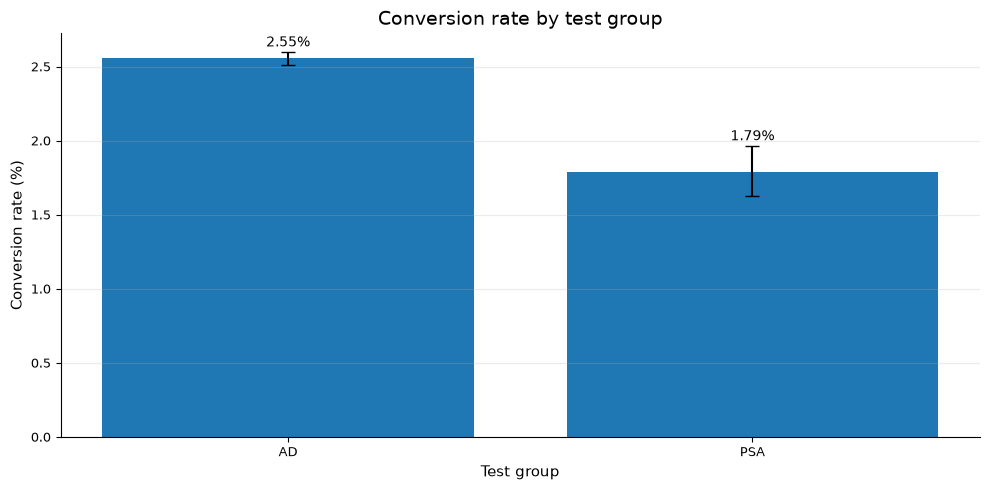

In [6]:
rate_intervals = [
    proportion_confint(x_ad, n_ad, method="wilson"),
    proportion_confint(x_psa, n_psa, method="wilson"),
]
rates = np.array([p_ad, p_psa]) * 100
lower_errors = np.array([rates[0] - rate_intervals[0][0] * 100,
                         rates[1] - rate_intervals[1][0] * 100])
upper_errors = np.array([rate_intervals[0][1] * 100 - rates[0],
                         rate_intervals[1][1] * 100 - rates[1]])

fig, ax = plt.subplots()
ax.bar(["AD", "PSA"], rates, yerr=np.vstack([lower_errors, upper_errors]), capsize=5)
ax.set_title("Conversion rate by test group")
ax.set_ylabel("Conversion rate (%)")
ax.set_xlabel("Test group")
ax.grid(axis="y", alpha=0.25)
for index, value in enumerate(rates):
    ax.text(index, value + upper_errors[index] + 0.04, f"{value:.2f}%", ha="center")
plt.tight_layout()
plt.show()

### 6.4 Interpretation

The AD group converted at approximately 2.55%, compared with 1.79% in the PSA group. The estimated absolute difference is about **+0.77 percentage points** (95% Newcombe CI: approximately +0.59 to +0.94 pp), with a relative lift of about **43.1%**. The two-sided test rejects equal conversion proportions.

This supports the statement that the AD group had a higher observed conversion rate in this dataset. A causal statement such as “ads caused the increase” additionally depends on credible random assignment, comparable measurement, and a documented experiment design.

## 7. Timing theory 1: does weekday matter?

This section is restricted to AD users. Each user contributes one binary conversion outcome and one recorded `most_ads_day` category.

### 7.1 Weekday conversion-rate table

,users,conversions,conversion_rate_pct,share_of_ad_users_pct
most_ads_day,,,,
Monday,83571,2778,3.3241,14.8024
Tuesday,74572,2270,3.0440,13.2085
Wednesday,77418,1963,2.5356,13.7126
Thursday,79077,1711,2.1637,14.0064
Friday,88805,1995,2.2465,15.7295
Saturday,78802,1679,2.1307,13.9577
Sunday,82332,2027,2.4620,14.5830


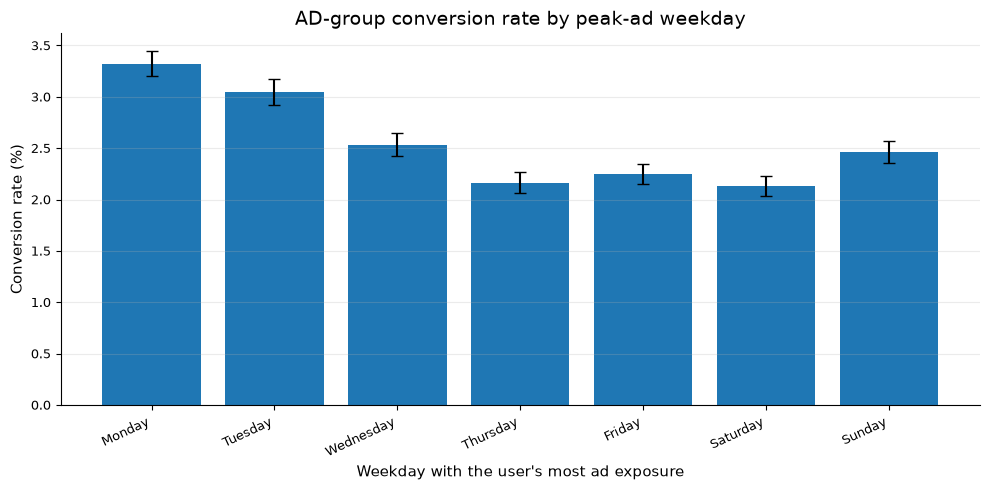

In [7]:
weekday_summary = (
    ad_users.groupby("most_ads_day", observed=False)["converted"]
    .agg(users="size", conversions="sum", conversion_rate="mean")
    .reindex(weekday_order)
)
weekday_summary["conversion_rate_pct"] = weekday_summary["conversion_rate"] * 100
weekday_summary["share_of_ad_users_pct"] = weekday_summary["users"] / len(ad_users) * 100
display(weekday_summary[["users", "conversions", "conversion_rate_pct", "share_of_ad_users_pct"]])

weekday_intervals = np.array([
    proportion_confint(int(row.conversions), int(row.users), method="wilson")
    for row in weekday_summary.itertuples()
])
weekday_rates = weekday_summary["conversion_rate_pct"].to_numpy()
weekday_yerr = np.vstack([
    weekday_rates - weekday_intervals[:, 0] * 100,
    weekday_intervals[:, 1] * 100 - weekday_rates,
])

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(weekday_order, weekday_rates, yerr=weekday_yerr, capsize=4)
ax.set_title("AD-group conversion rate by peak-ad weekday")
ax.set_ylabel("Conversion rate (%)")
ax.set_xlabel("Weekday with the user's most ad exposure")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 7.2 Global chi-square test

In [8]:
weekday_table = pd.crosstab(ad_users["most_ads_day"], ad_users["converted"]).reindex(weekday_order)
weekday_chi2, weekday_p, weekday_dof, weekday_expected = chi2_contingency(
    weekday_table, correction=False
)
weekday_cramers_v = np.sqrt(weekday_chi2 / weekday_table.to_numpy().sum())

print(f"Chi-square statistic: {weekday_chi2:.4f}")
print(f"Degrees of freedom: {weekday_dof}")
print(f"p-value: {weekday_p:.4e}")
print(f"Cramer's V: {weekday_cramers_v:.4f}")
print(f"Minimum expected cell count: {weekday_expected.min():.2f}")

Chi-square statistic: 412.7943
Degrees of freedom: 6
p-value: 4.9595e-86
Cramer's V: 0.0270
Minimum expected cell count: 1905.06


**Interpretation:** the global test provides evidence that conversion outcome and recorded peak-ad weekday are associated. Cramér's V is small (about 0.027), so the association is statistically detectable but modest in magnitude. The test does not identify which specific weekdays differ; that requires post-hoc comparisons.

### 7.3 Post-hoc weekday comparisons: all 21 pairs

In [9]:
weekday_pair_rows = []
for day_a, day_b in combinations(weekday_order, 2):
    sample_a = ad_users.loc[ad_users["most_ads_day"] == day_a, "converted"].astype(int)
    sample_b = ad_users.loc[ad_users["most_ads_day"] == day_b, "converted"].astype(int)
    _, p_raw = proportions_ztest(
        count=[int(sample_a.sum()), int(sample_b.sum())],
        nobs=[len(sample_a), len(sample_b)],
        alternative="two-sided",
    )
    weekday_pair_rows.append({
        "day_a": day_a,
        "day_b": day_b,
        "rate_a_pct": sample_a.mean() * 100,
        "rate_b_pct": sample_b.mean() * 100,
        "difference_a_minus_b_pp": (sample_a.mean() - sample_b.mean()) * 100,
        "p_value_raw": p_raw,
    })

weekday_pairs = pd.DataFrame(weekday_pair_rows)
weekday_pairs["p_value_holm"] = multipletests(
    weekday_pairs["p_value_raw"], method="holm"
)[1]
weekday_pairs = weekday_pairs.sort_values("p_value_holm").reset_index(drop=True)
display(weekday_pairs.head(12))

monday_tuesday = weekday_pairs.query(
    "day_a == 'Monday' and day_b == 'Tuesday'"
).iloc[0]
print("\nMonday vs Tuesday (two-sided, selected from the full 21-pair family):")
print(f"Rate difference: {monday_tuesday['difference_a_minus_b_pp']:.4f} pp")
print(f"Raw p-value: {monday_tuesday['p_value_raw']:.6f}")
print(f"Holm-adjusted p-value: {monday_tuesday['p_value_holm']:.6f}")

# A nominal 95% Newcombe interval for the Monday-Tuesday difference.
# It is unadjusted for the family of 21 comparisons, unlike the Holm p-value.
mon = ad_users.loc[ad_users["most_ads_day"] == "Monday", "converted"].astype(int)
tue = ad_users.loc[ad_users["most_ads_day"] == "Tuesday", "converted"].astype(int)
mon_tue_ci = confint_proportions_2indep(
    int(mon.sum()), len(mon), int(tue.sum()), len(tue),
    method="newcomb", compare="diff", alpha=0.05,
)
print(f"Nominal (unadjusted) 95% CI: [{mon_tue_ci[0] * 100:.4f}, {mon_tue_ci[1] * 100:.4f}] pp")

,day_a,day_b,rate_a_pct,rate_b_pct,difference_a_minus_b_pp,p_value_raw,p_value_holm
0,Monday,Saturday,3.3241,2.1307,1.1935,0.0000,0.0000
1,Monday,Thursday,3.3241,2.1637,1.1604,0.0000,0.0000
2,Monday,Friday,3.3241,2.2465,1.0776,0.0000,0.0000
3,Tuesday,Saturday,3.0440,2.1307,0.9134,0.0000,0.0000
4,Tuesday,Thursday,3.0440,2.1637,0.8803,0.0000,0.0000
5,Monday,Sunday,3.3241,2.4620,0.8621,0.0000,0.0000
6,Tuesday,Friday,3.0440,2.2465,0.7975,0.0000,0.0000
7,Monday,Wednesday,3.3241,2.5356,0.7885,0.0000,0.0000
8,Tuesday,Sunday,3.0440,2.4620,0.5821,0.0000,0.0000
9,Tuesday,Wednesday,3.0440,2.5356,0.5085,0.0000,0.0000



Monday vs Tuesday (two-sided, selected from the full 21-pair family):
Rate difference: 0.2801 pp
Raw p-value: 0.001562
Holm-adjusted p-value: 0.009372
Nominal (unadjusted) 95% CI: [0.1067, 0.4531] pp


### 7.4 Weekday conclusion

Monday has the highest observed conversion rate (about **3.32%**) and Tuesday ranks second (about **3.04%**). The Monday–Tuesday difference remains statistically significant after Holm correction across all 21 weekday pairwise tests (adjusted p ≈ **0.00937**).

This is a stronger conclusion than simply selecting the highest bar. However, the weekday variable is still the user's peak-ad-exposure weekday, not a randomized ad-scheduling assignment or conversion timestamp. The result is an association that motivates a controlled timing experiment; it is not proof that moving budget to Monday would cause a lift.

## 8. Timing theory 2: does hour matter?

Again, this analysis uses AD users only. `most_ads_hour` is a 0–23 hour label associated with the user's peak ad exposure. The source does not document a timezone, so no local-time behavioural interpretation is assumed.

### 8.1 Hourly conversion rates

,users,conversions,conversion_rate_pct,share_of_ad_users_pct
most_ads_hour,,,,
16,35963,1111,3.0893,6.3699
20,27846,843,3.0274,4.9322
15,42855,1279,2.9845,7.5906
21,28895,843,2.9175,5.1180
14,43779,1251,2.8575,7.7543
17,33605,959,2.8537,5.9522
18,31052,853,2.7470,5.5000
19,29169,782,2.6809,5.1665
22,25515,675,2.6455,4.5193


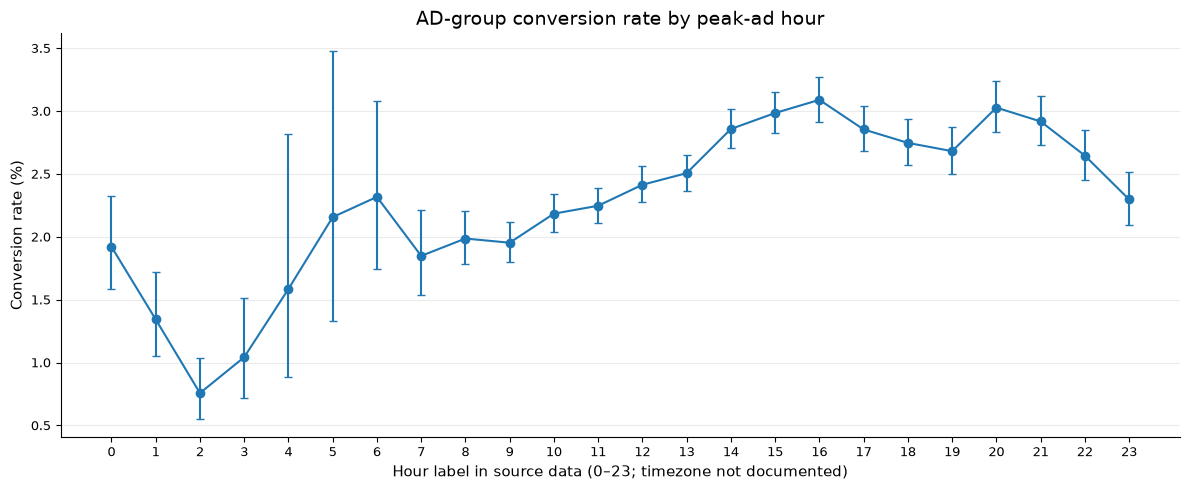

In [10]:
hour_order = list(range(24))
hourly_summary = (
    ad_users.groupby("most_ads_hour")["converted"]
    .agg(users="size", conversions="sum", conversion_rate="mean")
    .reindex(hour_order)
)
hourly_summary["conversion_rate_pct"] = hourly_summary["conversion_rate"] * 100
hourly_summary["share_of_ad_users_pct"] = hourly_summary["users"] / len(ad_users) * 100
display(hourly_summary.sort_values("conversion_rate", ascending=False).head(10)[
    ["users", "conversions", "conversion_rate_pct", "share_of_ad_users_pct"]
])

hour_intervals = np.array([
    proportion_confint(int(row.conversions), int(row.users), method="wilson")
    for row in hourly_summary.itertuples()
])
hour_rates = hourly_summary["conversion_rate_pct"].to_numpy()
hour_yerr = np.vstack([
    hour_rates - hour_intervals[:, 0] * 100,
    hour_intervals[:, 1] * 100 - hour_rates,
])

fig, ax = plt.subplots(figsize=(12, 5))
ax.errorbar(hour_order, hour_rates, yerr=hour_yerr, fmt="o-", capsize=3)
ax.set_title("AD-group conversion rate by peak-ad hour")
ax.set_xlabel("Hour label in source data (0–23; timezone not documented)")
ax.set_ylabel("Conversion rate (%)")
ax.set_xticks(hour_order)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### 8.2 Global chi-square test

In [11]:
hour_table = pd.crosstab(ad_users["most_ads_hour"], ad_users["converted"]).reindex(hour_order)
hour_chi2, hour_p, hour_dof, hour_expected = chi2_contingency(
    hour_table, correction=False
)
hour_cramers_v = np.sqrt(hour_chi2 / hour_table.to_numpy().sum())

print(f"Chi-square statistic: {hour_chi2:.4f}")
print(f"Degrees of freedom: {hour_dof}")
print(f"p-value: {hour_p:.4e}")
print(f"Cramer's V: {hour_cramers_v:.4f}")
print(f"Minimum expected cell count: {hour_expected.min():.2f}")

Chi-square statistic: 403.3270
Degrees of freedom: 23
p-value: 3.6713e-71
Cramer's V: 0.0267
Minimum expected cell count: 17.73


The global result indicates that conversion outcomes are not distributed identically across all 24 recorded peak-ad hours. Cramér's V is again small (about 0.027). The global p-value does **not** prove that the top-ranked hour is better than the runner-up.

### 8.3 Post-hoc hourly comparisons: all 276 pairs

In [12]:
hour_pair_rows = []
for hour_a, hour_b in combinations(hour_order, 2):
    sample_a = ad_users.loc[ad_users["most_ads_hour"] == hour_a, "converted"].astype(int)
    sample_b = ad_users.loc[ad_users["most_ads_hour"] == hour_b, "converted"].astype(int)
    _, p_raw = proportions_ztest(
        count=[int(sample_a.sum()), int(sample_b.sum())],
        nobs=[len(sample_a), len(sample_b)],
        alternative="two-sided",
    )
    hour_pair_rows.append({
        "hour_a": hour_a,
        "hour_b": hour_b,
        "rate_a_pct": sample_a.mean() * 100,
        "rate_b_pct": sample_b.mean() * 100,
        "difference_a_minus_b_pp": (sample_a.mean() - sample_b.mean()) * 100,
        "p_value_raw": p_raw,
    })

hour_pairs = pd.DataFrame(hour_pair_rows)
hour_pairs["p_value_holm"] = multipletests(
    hour_pairs["p_value_raw"], method="holm"
)[1]
hour_pairs = hour_pairs.sort_values("p_value_holm").reset_index(drop=True)

# Observed top hour, second-ranked hour, and their comparison.
top_hour = int(hourly_summary["conversion_rate"].idxmax())
ranked_hours = hourly_summary.sort_values("conversion_rate", ascending=False)
second_hour = int(ranked_hours.index[1])
top_rate = float(ranked_hours.iloc[0]["conversion_rate"])
second_rate = float(ranked_hours.iloc[1]["conversion_rate"])

first_second = hour_pairs.loc[
    ((hour_pairs["hour_a"] == top_hour) & (hour_pairs["hour_b"] == second_hour)) |
    ((hour_pairs["hour_a"] == second_hour) & (hour_pairs["hour_b"] == top_hour))
].iloc[0]

print(f"Top observed hour: {top_hour:02d}:00 ({top_rate * 100:.4f}%)")
print(f"Second observed hour: {second_hour:02d}:00 ({second_rate * 100:.4f}%)")
print(f"Observed difference: {(top_rate - second_rate) * 100:.4f} pp")
print(f"Top-vs-second raw p-value: {first_second['p_value_raw']:.6f}")
print(f"Top-vs-second Holm-adjusted p-value (276-pair family): {first_second['p_value_holm']:.6f}")

# Show comparisons among the five leading observed hours.
top_five_hours = [int(hour) for hour in ranked_hours.head(5).index]
leading_hour_pairs = hour_pairs[
    hour_pairs["hour_a"].isin(top_five_hours) & hour_pairs["hour_b"].isin(top_five_hours)
].sort_values("p_value_holm")
display(leading_hour_pairs)

Top observed hour: 16:00 (3.0893%)
Second observed hour: 20:00 (3.0274%)
Observed difference: 0.0619 pp
Top-vs-second raw p-value: 0.652539
Top-vs-second Holm-adjusted p-value (276-pair family): 1.000000


,hour_a,hour_b,rate_a_pct,rate_b_pct,difference_a_minus_b_pp,p_value_raw,p_value_holm
179,20,21,3.0274,2.9175,0.1099,0.4408,1.0000
245,14,15,2.8575,2.9845,-0.1269,0.2672,1.0000
246,14,16,2.8575,3.0893,-0.2318,0.0548,1.0000
250,14,20,2.8575,3.0274,-0.1698,0.1885,1.0000
251,14,21,2.8575,2.9175,-0.0599,0.6365,1.0000
253,15,16,2.9845,3.0893,-0.1048,0.3927,1.0000
254,16,21,3.0893,2.9175,0.1718,0.2032,1.0000
261,15,20,2.9845,3.0274,-0.0429,0.7440,1.0000
262,15,21,2.9845,2.9175,0.0670,0.6032,1.0000
266,16,20,3.0893,3.0274,0.0619,0.6525,1.0000


### 8.4 Hourly conclusion

**16:00** has the highest observed conversion rate (about **3.09%**), with **20:00** second (about **3.03%**). Their observed difference is only about **0.062 percentage points**. The pairwise comparison is not significant even before correction (raw p ≈ 0.653), and is not significant after Holm correction across all 276 hourly comparisons (adjusted p = 1.00).

Several leading hours form a close afternoon/evening cluster. The analysis does not justify declaring 16:00 a uniquely optimal hour. The dataset also does not establish that the 16:00 pattern represents commuting or that 20:00 represents dinner-time browsing; those are behavioural explanations to test, not facts observed in these columns.

## 9. Business interpretation & next experiment

### What the evidence supports

- The AD group has a higher observed conversion rate than the PSA group.
- Among AD users, recorded peak-ad weekday is associated with conversion; Monday leads the observed ranking and beats Tuesday after multiple-testing correction.
- Among AD users, recorded peak-ad hour is associated with conversion; 16:00 leads descriptively, but it does not distinguish itself from the other leading candidates.
- The timing patterns are useful for generating a follow-up experiment, not for making a causal scheduling recommendation.

### Proposed randomized timing experiment

A follow-up test could compare pre-defined exposure windows such as **16:00–18:00** and **20:00–21:00**, with a suitable comparison window or business-as-usual control.

To isolate timing:

1. Randomly assign eligible users (or non-overlapping user cohorts) to timing arms before exposure.
2. Keep audience eligibility, creative, offer, bidding strategy, frequency caps, campaign dates, and attribution window comparable.
3. Prevent users from entering multiple timing arms where practical; define how repeat exposure and cross-device activity are handled.
4. Pre-register one primary outcome and the key pairwise comparisons; determine sample size and power before launch.
5. Measure conversion rate alongside cost per conversion, incremental conversions, revenue, and return on ad spend.

A statistically significant conversion-rate improvement is not automatically a profitable improvement. Budget decisions require cost and revenue data.

## 10. Limitations & threats to validity

1. **Randomization is undocumented in the available extract.** The label “A/B test” and the two group names do not, by themselves, establish successful random assignment or allocation integrity.
2. **Unequal group sizes.** About 96% of users are in AD and 4% in PSA. This does not automatically invalidate the test, but the planned allocation and any sample loss should be checked.
3. **No conversion timestamp or attribution-window documentation.** Peak ad day/hour is not the time at which conversion happened.
4. **No timezone metadata.** Hour labels cannot safely be translated into local-life behaviours such as commuting or dinner.
5. **No cost or revenue data.** Conversion rate alone cannot determine campaign profitability or ROI.
6. **Exposure variables may be post-assignment.** `total ads`, `most ads day`, and `most ads hour` should not be treated as baseline confounders or causal levers without a clear causal design. The timing analyses are descriptive/associational.
7. **Multiple comparisons.** Weekday and hour follow-ups use Holm correction across all 21 and 276 pairwise tests respectively. Even with correction, exploratory findings should be confirmed in a new experiment.
8. **Small effect-size measures for timing associations.** Very small p-values are partly enabled by the large sample. Cramér's V is around 0.027 for both timing dimensions, so practical impact deserves separate assessment.

## 11. Final conclusion

The dataset provides strong statistical evidence that the AD group has a higher observed conversion rate than the PSA group. Follow-up analyses show that weekday and peak-ad-hour categories are associated with conversion outcomes among AD users. Monday is the strongest observed weekday and statistically outperforms Tuesday after correction for multiple comparisons. 16:00 is the strongest observed hour, but it does not statistically outperform the other leading hours.

**Decision:** treat Monday and the late-afternoon/evening window as candidates for a controlled timing experiment—not as proven optimal scheduling rules. The next step is better experimental design and business-outcome measurement, not stronger causal language.

## Appendix: reproducibility checklist

- [ ] Download `marketing_AB.csv` from the Kaggle source and place it in `data/`.
- [ ] Install dependencies from `requirements.txt`.
- [ ] Run every cell from top to bottom.
- [ ] Confirm the data-quality assertions pass.
- [ ] Check that summary counts and statistical outputs match the notebook outputs committed to the repository.
- [ ] Treat timing findings as exploratory until validated with a randomized scheduling test.

**Reproducibility note:** the CSV is not committed to this repository. The notebook reads a local copy supplied by the user.